# DS1 1q payload noise

## Overview
Every 1q calibration payload keeps its fit, so it tells us how precisely that step measured its value - a noise estimate that doesn't depend on how the value moves between runs ([Phase 01, B3](../../docs/phases/01_eda.md#b3-ds1-measurements)). That's what we need to tell B2's run-to-run steps apart from noise. The payload format is in [datasheet 1](../../docs/datasheets/01_measurements_database.md).

**Question.** How big is the fit error of a 1q calibration step, does it explain the scatter within a run, and against it, do frequency, amp and DRAG move more than noise between runs?

**Method.** We decode the Ramsey, FineFrequency, FineFreqShift, XPi2Amp and XPi2Drag payloads the run map claims, check them against their own fits, and set the strata (section 1). Then we look at coverage (section 2) and the fit sd per ladder step (section 3). Section 4 checks whether the fit sd explains the scatter between steps of one run and builds σ per qubit and stratum. Section 5 compares B2's run-to-run σ against it, checks the noise holds still over time, tests amp together with the DS2 drive scale, and writes the σ to `noise_floor.parquet`. Rabi's left out - it writes no param and DS2 has no noise row for it.


In [1]:
import hashlib
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import decode, periods
from qpu_drift.derived.noise import load_noise_floor, write_noise_rows
from qpu_drift.derived.run_map import load_run_entities, load_run_map, load_run_results
from qpu_drift.derived.run_map.constants import STEPS_1Q
from qpu_drift.paths import DERIVED, DS1_FETCH_ROOT, MEASUREMENT_PAYLOADS, RAW_RAMSEY, REPO_ROOT
from qpu_drift.sources.hardware_models import decode_value, load_values
from qpu_drift.sources.measurements import load_measurements

pd.set_option("display.max_rows", 300, "display.max_columns", 40, "display.width", 250, "display.max_colwidth", 100)
m = load_measurements()
ids = load_run_results()
ent = load_run_entities(routine="calibrate_1q")
noise = load_noise_floor()
SETTINGS_PATH = DERIVED / "measurements" / "config_settings.parquet"
settings = pd.read_parquet(SETTINGS_PATH)

FIG = REPO_ROOT / "docs" / "figures" / "eda"
PARAM = {"Ramsey": "1q.freq", "FineFrequency": "1q.freq", "XPi2Amp": "1q.amp", "XPi2Drag": "1q.drag",
         "FineFreqShift": "1q.freq_shift_amp"}
LADDER_FIELD = {"FineFrequency": "delay", "XPi2Amp": "N", "XPi2Drag": "N"}  # B3b
DETUNING = "detuning"  # Ramsey config field: new = old - f + detuning (maac)
LOCAL_ROOTS = {
    "raw_ramsey": (RAW_RAMSEY, "results/"),
    "benchmarking": (DS1_FETCH_ROOT, ""),
    "fetch root": (MEASUREMENT_PAYLOADS, ""),
}
SEG_DATE = {0: "0 (start)"} | {i: f"{i} ({b.at:%Y-%m-%d})" for i, b in enumerate(periods.BREAKS, 1)}  # as B2

def rsd(s: pd.Series) -> float:
    """Robust sd: 1.4826 x the median absolute deviation."""
    return 1.4826 * (s - s.median()).abs().median()

valid = ids[ids["valid"]]
claim = valid.drop_duplicates("result_id").set_index("result_id")[["routine", "start", "step"]]
claimed_targets = set(zip(valid["result_id"], valid["key"]))  # calibrate_1q keys are Q<n>, one per in-spec qubit
cl = m[m["measurement_type"].isin([*PARAM, "Rabi"])].join(claim.rename(columns={"start": "run_start"}), on="id", how="inner")
cl["path"] = None
for name, (root, prefix) in LOCAL_ROOTS.items():
    files = {prefix + p.relative_to(root).as_posix(): p for p in root.rglob("*.gz")}
    hit = cl["path"].isna() & cl["relative_filepath"].isin(files.keys())
    cl.loc[hit, "path"] = cl.loc[hit, "relative_filepath"].map(files)
print("claimed rows by type and run-map step (valid ids):")
display(pd.crosstab(cl["measurement_type"], cl["step"], margins=True))
print("claimed rows with a local payload, by type:", cl.groupby("measurement_type")["path"].count().to_dict())
print("run-map steps that write a param (STEPS_1Q):", STEPS_1Q)
print("DS2 noise rows per 1q param:", noise[(noise["source"] == "ds2") & noise["param"].str.startswith("1q.")]
      .groupby("param").size().to_dict())

claimed rows by type and run-map step (valid ids):


step,amp,drag,freq,freq_shift,rabi,ramsey,All
measurement_type,,,,,,,
FineFreqShift,0,0,0,1244,0,0,1244
FineFrequency,0,0,6951,0,0,0,6951
Rabi,0,0,0,0,2476,0,2476
Ramsey,0,0,0,0,0,2476,2476
XPi2Amp,9556,0,0,0,0,0,9556
XPi2Drag,0,7396,0,0,0,0,7396
All,9556,7396,6951,1244,2476,2476,30099


claimed rows with a local payload, by type: {'FineFreqShift': 1244, 'FineFrequency': 6951, 'Rabi': 2476, 'Ramsey': 2476, 'XPi2Amp': 9556, 'XPi2Drag': 7396}
run-map steps that write a param (STEPS_1Q): {'freq': ('ramsey', 'freq'), 'amp': ('amp',), 'drag': ('drag',)}
DS2 noise rows per 1q param: {'1q.amp': 224, '1q.drag': 205, '1q.freq': 205}


## 1. Provenance and strata

First, what we read and how far we trust it. We read a payload when its `id` is a valid run-map `result_id` and the file is local. `decode.extract` gives each target's `old`, `new`, `r2` and fit sd: for Ramsey that's the sd of `f`, and for the other four it's the sd of the crossing of the two line fits (`decode.crossing`), propagated from both fit covariances. `calibrate_1q` only stores a step's id for its in-spec qubits (B3b section 4), so a target is *claimed* only when its (`id`, `Q<n>`) pair is a run-map (`result_id`, `key`).

As a guard, we recompute each stored value from its fits - Ramsey `old − f + detuning` against `new`, and the crossing against `new − old` (FineFrequency, FineFreqShift) or `new` (XPi2Amp, XPi2Drag) - and need a match to $10^{-12}$ relative. We also check whether the Ramsey sweep changes with the config `time` field, which B3b left open.

A *chain* is the steps of one param, run and qubit in time order, each labelled by type and ladder setting. A final step is *applied* when its `new` is the run-map `new`. A target is *used* when it's claimed, passes the guard, has a finite positive fit sd, and its run sits outside `INCIDENTS` and the f01 flags. The stratum is `SETTLING` or the `BREAKS` segment, as in B2.


In [2]:
use_steps = {"ramsey", "freq", "freq_shift", "amp", "drag"}
local = cl[cl["path"].notna() & cl["measurement_type"].isin(PARAM) & cl["step"].isin(use_steps)].sort_values("time_start")
ladder = settings[settings["measurement_type"].map(LADDER_FIELD).eq(settings["field"])].set_index("id")["value"]
ramsey_time = settings[(settings["measurement_type"] == "Ramsey") & (settings["field"] == "time")].set_index("id")["value"]


def sweep_signature(x) -> str:
    """Points, first and last value and a short hash of a sweep array."""
    x = np.asarray(x, dtype=float).ravel()
    return f"{len(x)} pts {x.min():.3g} to {x.max():.3g} md5 {hashlib.md5(np.round(x, 15).tobytes()).hexdigest()[:8]}"


def same(a: float, b: float) -> bool:
    """Equal to 1e-12 relative."""
    return bool(np.isclose(a, b, rtol=1e-12, atol=0))


rows, errors = [], {}
t0 = time.time()
for r in local.itertuples():
    try:
        obj = decode.payload(r.path)
    except decode.PayloadError as exc:
        errors[r.id] = str(exc)
        continue
    nodes = dict(decode.iter_targets(obj))
    config = decode.plain(obj["dict"]["config"])
    for res in decode.extract(obj):
        node = nodes[res.target]
        x, n_fits, sweep = np.nan, 0, None
        if "fits" in node:
            n_fits = len(node["fits"])
            if n_fits == 2:
                try:
                    x, _ = decode.crossing(*[decode.fit_vector(fit) for fit in node["fits"]])
                except (ValueError, ZeroDivisionError, IndexError):
                    pass
        elif "fit" in node:
            n_fits = 1
            fv = decode.fit_vector(node["fit"])
            if "f" in fv.names:
                x = res.old - fv.value("f") + config[DETUNING]
            fd = decode.plain(node["fit"])
            sweep = sweep_signature(fd.get("xdata", fd.get("x_data")))
        rows.append((r.id, r.measurement_type, r.measurement_name, r.time_start, r.run_start, res.target,
                     res.old, res.new, res.error, res.r2, x, n_fits, sweep))
print(f"payloads decoded {len(local) - len(errors)} of {len(local)} in {time.time() - t0:.0f} s; decode errors {len(errors)}:",
      list(errors.items())[:5])
f = pd.DataFrame(rows, columns=["id", "type", "name", "time_start", "run_start", "target", "old", "new", "sd", "r2", "x",
                                "n_fits", "sweep"])
f["qubit"] = f["target"].str.extract(r"^Q(\d+)$")[0].astype("Int64")
f["param"] = f["type"].map(PARAM)
f["setting"] = f["id"].map(ladder).fillna("")
f["step_label"] = (f["type"] + " " + f["setting"]).str.strip()
f["sd"] = pd.to_numeric(f["sd"], errors="coerce")
f["claimed"] = [(i, t) in claimed_targets for i, t in zip(f["id"], f["target"])]
print("targets per type; fits per target node:")
display(pd.crosstab(f["type"], f["n_fits"], margins=True))
print("targets that are not a qubit (Q<n>):", f.loc[f["qubit"].isna(), "target"].value_counts().to_dict())
print("targets claimed by the run map for that qubit (the run stores a step's id only for its in-spec qubits):")
display(pd.crosstab(f["type"], f["claimed"], margins=True))

ref = np.where(f["type"].isin(["FineFrequency", "FineFreqShift"]), f["new"] - f["old"], f["new"])
f["guard_diff"] = (f["x"] - ref).abs()
f["guard"] = f["guard_diff"] <= 1e-12 * np.maximum(f["old"].abs(), f["new"].abs())
print("recomputed value vs stored (Ramsey: old - f + detuning vs new; FineFrequency, FineFreqShift: crossing vs new - old; "
      "XPi2Amp, XPi2Drag: crossing vs new). Match within 1e-12 of the value's size:")
display(f.groupby("type").agg(targets=("guard", "size"), match=("guard", "sum"), no_x=("x", lambda s: s.isna().sum()),
                              max_abs_diff=("guard_diff", "max")))
f["sd_ok"] = np.isfinite(f["sd"]) & (f["sd"] > 0)
print("fit sd per type: missing, infinite, zero, positive and finite:")
display(f.groupby("type")["sd"].agg(missing=lambda s: s.isna().sum(), inf=lambda s: np.isinf(s).sum(),
                                    zero=lambda s: (s == 0).sum(), ok=lambda s: (np.isfinite(s) & (s > 0)).sum()))
print("Ramsey payloads by sweep (fit x data) and whether the config has a 'time' field:")
rs = f[f["type"] == "Ramsey"].drop_duplicates("id")
display(pd.crosstab(rs["sweep"], rs["id"].map(ramsey_time).fillna("<not read>").ne("<absent>").rename("time present")))

f = f.sort_values(["param", "run_start", "qubit", "time_start"]).reset_index(drop=True)
chain = f.groupby(["param", "run_start", "qubit"])
f["k"] = chain.cumcount()
f["prev_new"], f["prev_sd"], f["prev_label"] = chain["new"].shift(), chain["sd"].shift(), chain["step_label"].shift()
f["link"] = np.where(f["prev_new"].isna(), "first",
                     np.where(np.isclose(f["old"], f["prev_new"], rtol=1e-12, atol=0), "old = previous new", "differs"))
print("chain links within a run and qubit (each step's old against the previous step's new):")
display(pd.crosstab(f["param"], f["link"]))
f["run_ladder"] = f["param"] + ": " + chain["step_label"].transform(" > ".join)
print("chains per param and ladder of steps:")
display(f.drop_duplicates(["param", "run_start", "qubit"])["run_ladder"].value_counts().to_frame("chains"))

f["final"] = f["k"] == chain["k"].transform("max")
key = ["param", "run_start", "qubit"]
ent_new = ent.dropna(subset=["qubit"]).assign(param="1q." + ent["param"]).set_index(["param", "start", "qubit"])[["new", "warned"]]
fin = (f[f["final"]].join(ent_new.rename(columns={"new": "ent_new"}), on=key)
       .join(chain["new"].agg(list).rename("news"), on=key).join(chain["old"].first().rename("first_old"), on=key))
fin["vs_run_map"] = [
    "no run-map new" if np.isnan(e) else "final step's new" if same(e, n)
    else "an earlier step's new" if any(same(e, v) for v in vs[:-1]) else "the chain's first old" if same(e, o) else "other"
    for e, n, vs, o in zip(fin["ent_new"], fin["new"], fin["news"], fin["first_old"])]
print("run-map new for each chain's run, qubit and param, matched to the chain's values; by run-map warning:")
display(pd.crosstab([fin["param"], fin["warned"].astype(str).rename("warned")], fin["vs_run_map"], margins=True))
print("the same by whether the final step is claimed for its qubit:")
display(pd.crosstab([fin["param"], fin["claimed"].rename("final claimed")], fin["vs_run_map"], margins=True))
f["applied"] = False
f.loc[fin.index, "applied"] = fin["vs_run_map"].eq("final step's new")

settling = periods.within(f["run_start"], *periods.SETTLING)
f["stratum"] = np.where(settling, "settling", pd.Series(periods.segment(f["run_start"])).map(SEG_DATE))
f["in_incident"] = periods.within(f["run_start"], *[i.period for i in periods.INCIDENTS])
f["f01_flag"] = periods.f01_flagged(f["run_start"], f["qubit"].fillna(-1).astype(int))
shift_q = set(zip(f.loc[f["type"] == "FineFreqShift", "run_start"], f.loc[f["type"] == "FineFreqShift", "qubit"]))
f["freq_shift_qubit"] = [(t, q) in shift_q for t, q in zip(f["run_start"], f["qubit"])]
f["use"] = f["claimed"] & f["guard"] & f["sd_ok"] & ~f["in_incident"] & ~f["f01_flag"]
print("targets per param: not claimed, guard failures, bad sd, in INCIDENTS, f01 flagged, on a freq-shift qubit, used:")
display(f.groupby("param").agg(targets=("use", "size"), not_claimed=("claimed", lambda s: (~s).sum()),
                               guard_fail=("guard", lambda s: (~s).sum()), sd_bad=("sd_ok", lambda s: (~s).sum()),
                               in_incident=("in_incident", "sum"), f01_flag=("f01_flag", "sum"),
                               freq_shift_qubit=("freq_shift_qubit", "sum"), use=("use", "sum")))
print("freq-shift qubits (a FineFreqShift target in the run): targets per type:")
display(pd.crosstab(f.loc[f["freq_shift_qubit"], "qubit"], f.loc[f["freq_shift_qubit"], "type"]))


payloads decoded 27623 of 27623 in 54 s; decode errors 0: []


targets per type; fits per target node:


n_fits,1,2,All
type,,,
FineFreqShift,0,2698,2698
FineFrequency,0,101252,101252
Ramsey,36918,0,36918
XPi2Amp,0,147922,147922
XPi2Drag,0,108216,108216
All,36918,360088,397006


targets that are not a qubit (Q<n>): {}
targets claimed by the run map for that qubit (the run stores a step's id only for its in-spec qubits):


claimed,False,True,All
type,,,
FineFreqShift,23,2675,2698
FineFrequency,1948,99304,101252
Ramsey,0,36918,36918
XPi2Amp,12115,135807,147922
XPi2Drag,1328,106888,108216
All,15414,381592,397006


...

vs_run_map                       an earlier step's new  final step's new  no run-map new  the chain's first old     All
param             final claimed                                                                                        
1q.amp            False                          11541                 0               0                    574   12115
                  True                               0             26883               0                      0   26883
1q.drag           False                            359                 0               0                    969    1328
                  True                               0             35454               0                      0   35454
1q.freq           False                           1947                 0               0                      1    1948
                  True                               0             34998               0                      0   34998
1q.freq_shift_amp False                              0                 0              23                      0      23
                  True                               0                 0            2675                      0    2675
All                                              13847             97335            2698                   1544  115424

targets per param: not claimed, guard failures, bad sd, in INCIDENTS, f01 flagged, on a freq-shift qubit, used:


,targets,not_claimed,guard_fail,sd_bad,in_incident,f01_flag,freq_shift_qubit,use
param,,,,,,,,
1q.amp,147922,12115,0,0,578,564,8054,135412
1q.drag,108216,1328,0,0,531,529,0,106474
1q.freq,138170,1948,0,6,806,796,0,135469
1q.freq_shift_amp,2698,23,0,0,26,22,2698,2653


freq-shift qubits (a FineFreqShift target in the run): targets per type:


type,FineFreqShift,XPi2Amp
qubit,,
2,1244,4432
13,1244,3349
23,210,273


**Results.**

- The run map claims rows of all six types, each at one step, and every one has a local payload. `STEPS_1Q` has no `rabi` and DS2 has no Rabi noise row, so Rabi stays out.
- All 27,623 payloads decode with no errors, and every target is a qubit. Ramsey has one fit per target, the others two.
- Most targets are claimed for their qubit. XPi2Amp has the most that aren't (12,115 of 147,922), then FineFrequency (1,948) and XPi2Drag (1,328); every Ramsey target is claimed.
- Every target passes the guard (the biggest gap is 4.8e-07 Hz, for FineFrequency), and only 6 Ramsey fit sds are bad (3 infinite, 3 zero).
- The Ramsey sweep is the same with and without `time` (2,136 and 340 payloads), so `time` doesn't need its own stratum.
- Each step's `old` is the previous step's `new` all the way down every chain. The usual ladders are amp `1 > 2 > 4 > 8`, drag `2 > 3 > 4` and freq `Ramsey > 1e-07 > 2.5e-07 > 5e-07`.
- Without a run-map warning, the run-map `new` is always the final step's `new`. With one, it's mostly an earlier step's `new` or the chain's first `old` - only 185 of the 12,300 warned amp chains apply their final step.
- A final step is claimed exactly when it's applied, so the claim marks what the run kept.
- After the exclusions we use 135,412 amp, 106,474 drag, 135,469 freq and 2,653 `freq_shift_amp` targets.
- FineFreqShift runs on Q2, Q13 and Q23 only, and those qubits have no Ramsey, FineFrequency or XPi2Drag in the same runs.


## 2. Coverage and missingness

Next, how much of each type we have per month, what share of it is used, and how many chains per month end in an applied final step.


In [3]:
f["month"] = f["run_start"].dt.to_period("M")
print("targets per type and month (all decoded):")
display(pd.crosstab(f["type"], f["month"]))
print("share of targets used (claimed for the qubit, guard, sd, outside INCIDENTS and f01 flags), per type and month:")
display(f.pivot_table(index="type", columns="month", values="use", aggfunc="mean").round(2))
print("chains per param and month whose final step was applied (equal to the run-map new):")
display(f[f["final"]].pivot_table(index="param", columns="month", values="applied", aggfunc="sum", fill_value=0))


targets per type and month (all decoded):


month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
type,,,,,,,,,,,,,,,,,,,,,,,,
FineFreqShift,6,60,168,183,186,91,88,110,122,120,124,124,116,124,116,122,124,108,64,120,114,118,124,66
FineFrequency,116,1160,3248,3536,3589,3010,3320,4591,5359,5268,5449,5450,5084,5444,5075,5366,5452,4747,2606,5283,4956,5143,5048,2952
Ramsey,58,580,1624,1769,1798,1221,1320,1602,1830,1800,1846,1860,1740,1860,1740,1830,1860,1620,926,1800,1680,1770,1764,1020
XPi2Amp,187,2449,6870,7513,7592,4966,5401,6513,7584,7360,5323,5793,7255,7719,7218,7634,7753,6749,3584,7468,6835,7276,7005,3875
XPi2Drag,174,1740,4872,5307,5394,3582,3814,4605,5364,5278,5449,5450,5092,5452,5079,5366,5456,4752,2618,5387,4840,5247,5132,2766


share of targets used (claimed for the qubit, guard, sd, outside INCIDENTS and f01 flags), per type and month:


month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
type,,,,,,,,,,,,,,,,,,,,,,,,
FineFreqShift,1.00,1.00,1.00,1.00,0.92,0.96,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.84,1.00,1.00,1.00,0.87,1.00
FineFrequency,0.97,0.98,0.99,0.99,0.99,0.98,0.97,0.97,0.99,0.99,0.99,0.99,0.98,0.99,0.99,0.99,0.99,0.99,0.89,0.98,0.98,0.97,0.92,0.97
Ramsey,1.00,1.00,1.00,1.00,1.00,1.00,0.99,0.98,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.87,1.00,1.00,1.00,0.92,1.00
XPi2Amp,0.96,0.93,0.93,0.92,0.91,0.90,0.92,0.91,0.92,0.92,0.90,0.90,0.92,0.92,0.92,0.93,0.93,0.93,0.86,0.92,0.90,0.92,0.87,0.91
XPi2Drag,1.00,1.00,1.00,1.00,1.00,0.99,0.97,0.97,0.99,0.99,0.99,0.99,0.99,0.99,0.99,0.99,0.99,0.99,0.90,1.00,0.99,0.99,0.93,0.99


chains per param and month whose final step was applied (equal to the run-map new):


month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
param,,,,,,,,,,,,,,,,,,,,,,,,
1q.amp,56,471,1343,1375,1337,833,967,1140,1353,1328,1200,1216,1306,1399,1292,1396,1437,1245,636,1292,1125,1285,1209,642
1q.drag,58,580,1624,1767,1797,1176,1240,1494,1763,1729,1787,1784,1669,1790,1671,1764,1796,1565,814,1785,1595,1698,1605,903
1q.freq,54,559,1583,1739,1749,1167,1225,1502,1756,1727,1788,1791,1661,1782,1668,1767,1794,1560,795,1674,1576,1608,1551,922
1q.freq_shift_amp,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


**Results.**

- Every type runs from 2024-09 to 2026-08. The thinnest months after 2024-10 are 2026-03 and 2026-08 (e.g. FineFrequency 2,606 and 2,952, against 4,591 to 5,452 from 2025-04 to 2026-02).
- Outside 2026-03 and 2026-07, 0.90 to 1.00 of each type is used - XPi2Amp is lowest, since it has the most unclaimed targets. Those two months hold the incidents and drop to 0.84 to 0.93.
- Applied final steps run from about 55 a month in 2024-09 up to 1,437 (amp) and about 1,800 (drag, freq). FineFreqShift has none, since it has no run-map `new`.


## 3. Marginals

Now the used targets per step (type and ladder setting): the fit sd, r², and the correction `new − old` relative to the fit sd. The figure shows the fit sd per param and step.


fit sd per step (type and ladder setting), used targets; native units, frequency in Hz:


,count,min,1%,5%,25%,50%,75%,95%,99%,max
step_label,,,,,,,,,,
FineFreqShift,2653,9.413e-05,0.000114,0.000127,0.0001499,0.000207,0.0002348,0.0003822,0.008987,0.3634
FineFrequency 1e-07,3.574e+04,5442,6897,7639,8840,9880,1.143e+04,2.047e+04,3.956e+04,5.586e+05
FineFrequency 2.5e-07,3.497e+04,2095,2866,3201,3734,4210,4950,9272,1.686e+04,2.651e+05
FineFrequency 5e-07,2.815e+04,1179,1494,1661,1959,2240,2712,5464,8397,1.483e+05
Ramsey,3.66e+04,3988,5854,6704,8262,9839,1.301e+04,2.821e+04,4.88e+04,1.985e+09
XPi2Amp 1,3.743e+04,2493,3837,4669,1.059e+04,1.342e+04,1.586e+04,2.746e+04,5.904e+04,3.131e+06
XPi2Amp 2,3.658e+04,1329,1847,2201,5190,6483,7586,1.316e+04,3.036e+04,1.574e+06
XPi2Amp 4,3.477e+04,665.9,919.1,1121,2666,3281,3821,6320,1.122e+04,5.389e+06
XPi2Amp 8,2.664e+04,345.2,467.6,569.4,1427,1722,2039,3861,9935,2.057e+05


r2 per step (the Fit schema to 2025-03 has none):


,count,min,1%,5%,25%,50%,75%,95%,99%,max
step_label,,,,,,,,,,
FineFreqShift,1940,0.9136,0.9642,0.9687,0.9741,0.9801,0.9876,0.9912,0.9932,0.995
FineFrequency 1e-07,2.819e+04,9.32e-05,0.592,0.839,0.9397,0.9549,0.9641,0.9734,0.9786,0.9874
FineFrequency 2.5e-07,2.757e+04,0.001702,0.6083,0.8201,0.9347,0.9517,0.9617,0.9718,0.9773,0.9876
FineFrequency 5e-07,2.7e+04,2.224e-05,0.5539,0.7387,0.9183,0.9436,0.9567,0.9689,0.9749,0.9844
Ramsey,2.898e+04,0.17,0.9524,0.9783,0.9954,0.9974,0.9982,0.9988,0.9991,0.9996
XPi2Amp 1,2.931e+04,1.389e-05,0.7761,0.9096,0.9733,0.9815,0.9863,0.9906,0.9927,0.9961
XPi2Amp 2,2.86e+04,0.0002355,0.7937,0.9232,0.9775,0.9856,0.9891,0.9922,0.9937,0.9969
XPi2Amp 4,2.724e+04,7.348e-05,0.8384,0.9489,0.9812,0.9866,0.9895,0.9924,0.9939,0.9964
XPi2Amp 8,2.094e+04,0.0003537,0.7703,0.93,0.9791,0.9858,0.9891,0.992,0.9937,0.9962


correction new - old per step: median, median |.|, robust sd; and the median of |correction| / fit sd:


,n,median,median_abs,rsd,median_abs_over_sd
step_label,,,,,
FineFreqShift,2653,-8.282e-06,0.0002369,0.0003489,1.142
FineFrequency 1e-07,35745,1.823e+04,3.615e+04,5e+04,3.529
FineFrequency 2.5e-07,34973,-1.286e+04,2.591e+04,3.633e+04,5.895
FineFrequency 5e-07,28153,-3303,8086,1.12e+04,3.416
Ramsey,36598,-2479,1.2e+04,1.759e+04,1.133
XPi2Amp 1,37432,2.041e+04,1.088e+05,1.594e+05,9.002
XPi2Amp 2,36579,-2509,1.535e+04,2.286e+04,2.543
XPi2Amp 4,34766,-530.3,7582,1.119e+04,2.445
XPi2Amp 8,26635,-516.5,4380,6423,2.637


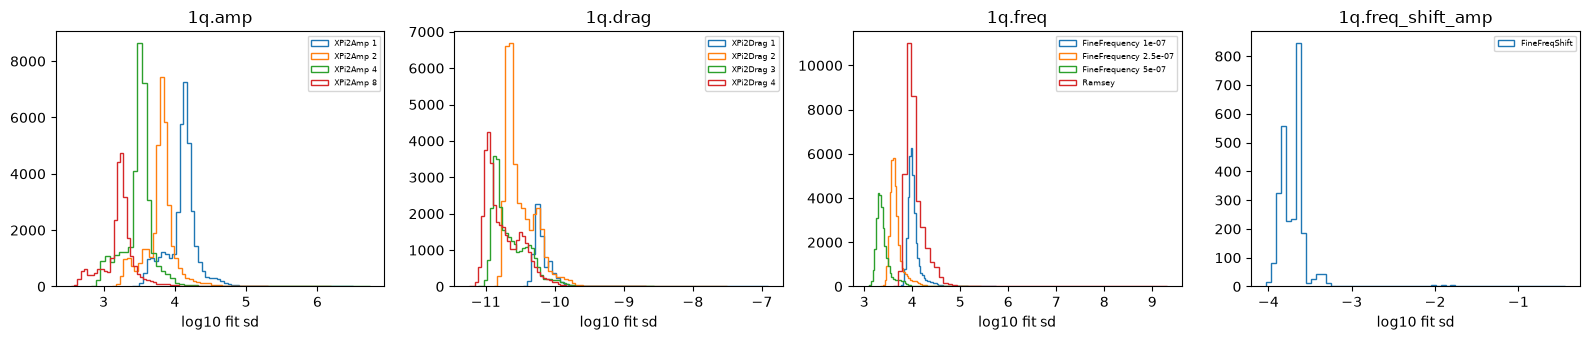

In [4]:
u = f[f["use"]]
q = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
print("fit sd per step (type and ladder setting), used targets; native units, frequency in Hz:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(u.groupby("step_label")["sd"].describe(percentiles=q).drop(columns=["mean", "std"]))
print("r2 per step (the Fit schema to 2025-03 has none):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(u.groupby("step_label")["r2"].describe(percentiles=q).drop(columns=["mean", "std"]))
corr = u["new"] - u["old"]
print("correction new - old per step: median, median |.|, robust sd; and the median of |correction| / fit sd:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(u.assign(corr=corr, rel=corr.abs() / u["sd"]).groupby("step_label").agg(
        n=("corr", "size"), median=("corr", "median"), median_abs=("corr", lambda s: s.abs().median()),
        rsd=("corr", rsd), median_abs_over_sd=("rel", "median")))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (p, g) in zip(axes, u.groupby("param")):
    for lab, h in g.groupby("step_label"):
        ax.hist(np.log10(h["sd"]), bins=60, histtype="step", label=lab)
    ax.set_title(p)
    ax.set_xlabel("log10 fit sd")
    ax.legend(fontsize=6)
fig.tight_layout()
fig.savefig(FIG / "b3c_fit_sd.png", dpi=150)
plt.show()

**Results.**

- The fit sd falls along each ladder: XPi2Amp halves at each step from 1.34e+04 at `1` to 1,722 at `8`, FineFrequency goes from 9,880 Hz at `1e-07` to 2,240 Hz at `5e-07`, and XPi2Drag from 6.05e-11 at `1` to 1.51e-11 at `4`. Ramsey (9,839 Hz) sits level with the first FineFrequency step.
- Every step has a long upper tail, with the max far above the 99th percentile (e.g. Ramsey 1.985e+09 Hz against 4.88e+04), so we stick to medians.
- r² is missing for payloads up to 2025-03; where it's there, the median is 0.94 to 1.00.
- The median correction is about 1.1 fit sd for Ramsey and FineFreqShift, and 2.4 to 9 for the ladder steps.


## 4. Noise floor

If the fit sd is all the measurement noise and the value holds still within a run, consecutive steps of a chain should differ by about their combined fit sd. For consecutive used steps (the later `old` being the earlier `new`):

$$d = \text{new}_k - \text{new}_{k-1}, \qquad z = \frac{d}{\sqrt{\text{sd}_k^2 + \text{sd}_{k-1}^2}}$$

so $z$ should have median 0 and robust sd rsd($z$) = 1. The *pooled scale* is rsd($z$) per param over the pairs ending at an applied final step. Ladder steps can also sit at a fixed offset from each other, so we also centre each pair on its typical offset:

$$z_c = \frac{d - \operatorname{median} d}{\sqrt{\text{sd}_k^2 + \text{sd}_{k-1}^2}}$$

with the median over the same param, qubit, stratum and step pair (n ≥ 20). The *centred scale* is rsd($z_c$) per param, stratum and final setting, again over pairs ending at an applied final step. We key it by the final setting rather than the whole ladder, since which steps get claimed depends on fit outcomes (B3b section 4).

Then σ per param, qubit, stratum and final setting is the median fit sd of the applied final steps (n ≥ 20, as in B2), and the *centred scaled σ* is the median of fit sd × centred scale. FineFreqShift runs one step per run, so for it we also take the lag-1 σ straight from the payloads - the robust sd of the run-to-run step over $\sqrt{2}$, as in B2. Both σ go to `noise_floor.parquet` as `ds1_1q` rows, written in section 5.


In [5]:
MIN_N = 20  # as B2
pairs = f[f["use"] & f["prev_new"].notna() & np.isfinite(f["prev_sd"]) & (f["prev_sd"] > 0)
          & (f["link"] == "old = previous new")].copy()
pairs["d"] = pairs["new"] - pairs["prev_new"]
pairs["pred"] = np.hypot(pairs["sd"], pairs["prev_sd"])
pairs["z"] = pairs["d"] / pairs["pred"]
pairs["pair"] = pairs["prev_label"] + " -> " + pairs["step_label"]
print("consecutive steps in a chain: d = new_k - new_(k-1), pred = sqrt(sd_k^2 + sd_(k-1)^2), z = d / pred:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(pairs.groupby(["param", "pair"]).agg(n=("z", "size"), median_d=("d", "median"), rsd_d=("d", rsd),
                                                 median_pred=("pred", "median"), median_z=("z", "median"), rsd_z=("z", rsd)))
last = pairs[pairs["final"] & pairs["applied"]]
scale = last.groupby("param")["z"].agg(rsd)
print("pooled sd scale: rsd(z) of the pairs ending at an applied final step, per param:", scale.round(3).to_dict())
print("the same per stratum:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(last.groupby(["param", "stratum"])["z"].agg(rsd).unstack("stratum"))

cgrp = pairs.groupby(["param", "qubit", "stratum", "pair"])["d"]
pairs["z_c"] = ((pairs["d"] - cgrp.transform("median")) / pairs["pred"]).where(cgrp.transform("size") >= MIN_N)
print(f"centred: z_c = (d - median d of the same param, qubit, stratum and pair) / pred, groups with n >= {MIN_N}; "
      "median z and rsd(z) against rsd(z_c) per param and pair:")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(pairs.groupby(["param", "pair"]).agg(n=("z", "size"), n_centred=("z_c", "count"), median_z=("z", "median"),
                                                 rsd_z=("z", rsd), rsd_z_c=("z_c", lambda s: rsd(s.dropna()))))
last = pairs[pairs["final"] & pairs["applied"] & pairs["z_c"].notna()]
scale_c = last.groupby(["param", "stratum", "step_label"])["z_c"].agg(n="size", rsd_z_c=rsd)
scale_c = scale_c[scale_c["n"] >= MIN_N]
print(f"centred sd scale per param, stratum and final setting: rsd(z_c) of the pairs ending at an applied final step "
      f"(n >= {MIN_N}):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(scale_c)

fa = f[f["use"] & f["final"] & f["applied"] & (f["param"] != "1q.freq_shift_amp")]
fa = fa.assign(sd_c=fa["sd"] * pd.Series(list(zip(fa["param"], fa["stratum"], fa["step_label"])), index=fa.index)
               .map(scale_c["rsd_z_c"]))
print("applied final steps (used) per param, final setting and stratum:")
display(pd.crosstab([fa["param"], fa["step_label"]], fa["stratum"]))
print("share of applied final steps with a centred scale for their stratum and final setting, per param:",
      fa.groupby("param")["sd_c"].apply(lambda s: s.notna().mean()).round(4).to_dict())
fl = fa.groupby(["param", "qubit", "stratum", "step_label"]).agg(
    sigma=("sd", "median"), sigma_scaled_c=("sd_c", "median"), n=("sd", "size"), n_scaled_c=("sd_c", "count"),
    start=("run_start", "min"), end=("run_start", "max")).reset_index()
fl = fl[fl["n"] >= MIN_N]
fl["sigma_scaled"] = fl["sigma"] * fl["param"].map(scale)
fl["sigma_scaled_c"] = fl["sigma_scaled_c"].where(fl["n_scaled_c"] >= MIN_N)
print(f"per-qubit median final-step fit sd (n >= {MIN_N}): qubits and median over qubits per param, final setting and stratum; "
      "sigma_scaled = x pooled scale, sigma_scaled_c = median of sd x centred scale (n >= 20 scaled steps):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(fl.groupby(["param", "step_label", "stratum"]).agg(qubits=("qubit", "size"), sigma=("sigma", "median"),
                                                              sigma_scaled=("sigma_scaled", "median"),
                                                              sigma_scaled_c=("sigma_scaled_c", "median"), n=("n", "sum")))
main = fl.sort_values("n").drop_duplicates(["param", "qubit", "stratum"], keep="last")
print(f"param, qubit and stratum groups with more than one final setting at n >= {MIN_N}:", len(fl) - len(main))

fs = f[f["use"] & (f["type"] == "FineFreqShift")].sort_values(["qubit", "run_start"])
fs = fs.assign(prev_run_new=fs.groupby("qubit")["new"].shift())
print("FineFreqShift used targets:", len(fs), "| old equal to the previous run's new:",
      int(np.isclose(fs["old"], fs["prev_run_new"], rtol=1e-12, atol=0).sum()))
fs = fs[np.isclose(fs["old"], fs["prev_run_new"], rtol=1e-12, atol=0)]
fs["run_step"] = fs["new"] - fs["prev_run_new"]
fsr = fs.groupby(["qubit", "stratum"]).agg(sigma_step=("run_step", lambda s: rsd(s) / np.sqrt(2)), sigma=("sd", "median"),
                                          n=("sd", "size"), start=("run_start", "min"), end=("run_start", "max")).reset_index()
fsr = fsr[fsr["n"] >= MIN_N].assign(ratio=lambda d: (d["sigma_step"] / d["sigma"]) ** 2)
print(f"FineFreqShift per qubit and stratum (n >= {MIN_N}): lag-1 sigma = robust sd(new - previous run's new) / sqrt(2), "
      "median fit sd, ratio = (lag-1 sigma / fit sd)^2 (noise alone gives 1):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(fsr)

rows_out = pd.concat([
    main.assign(method="final_step_fit_sd_median"),
    main.dropna(subset=["sigma_scaled_c"]).assign(sigma=lambda d: d["sigma_scaled_c"], n=lambda d: d["n_scaled_c"],
                                                  method="final_step_fit_sd_median_x_rsd_zc"),
    fsr.assign(param="1q.freq_shift_amp", method="final_step_fit_sd_median"),
    fsr.assign(param="1q.freq_shift_amp", sigma=fsr["sigma_step"], method="payload_step_robust_sd_over_sqrt2"),
])
rows_out = rows_out.assign(source="ds1_1q", entity=rows_out["qubit"].astype(str), regime=rows_out["stratum"],
                           unit=np.where(rows_out["param"] == "1q.freq", "Hz", "native"))
print(f"{len(rows_out)} ds1_1q rows from this section (written with the amp x scale rows at the end of section 5). "
      "Rows per param and method:")
display(rows_out.groupby(["param", "method"]).size().to_frame("rows"))


consecutive steps in a chain: d = new_k - new_(k-1), pred = sqrt(sd_k^2 + sd_(k-1)^2), z = d / pred:


n   median_d     rsd_d  median_pred  median_z  rsd_z
param   pair                                                                                                  
1q.amp  XPi2Amp 1 -> XPi2Amp 2                        36579      -2509 2.286e+04    1.499e+04   -0.2021   1.63
        XPi2Amp 2 -> XPi2Amp 4                        34342     -616.7 1.099e+04         7316   -0.1011   1.58
        XPi2Amp 4 -> XPi2Amp 8                        26261     -551.7      6296         3736   -0.1788  1.754
1q.drag XPi2Drag 1 -> XPi2Drag 2                       6893  1.084e-10 1.201e-10    6.632e-11     1.524  1.727
        XPi2Drag 2 -> XPi2Drag 3                      28646  5.773e-11 1.347e-10    3.238e-11     1.576  3.629
        XPi2Drag 2 -> XPi2Drag 4                       6885  2.088e-10 2.228e-10    3.264e-11     6.071  7.679
        XPi2Drag 3 -> XPi2Drag 4                      28434  4.703e-11 1.269e-10    2.456e-11     1.744   4.98
1q.freq FineFrequency 1e-07 -> FineFrequency 2.5e-07  34960 -1.287e+04 3.632e+04     1.07e+04     -1.18  3.321
        FineFrequency 2.5e-07 -> FineFrequency 5e-07  28153      -3303  1.12e+04         4806   -0.6621  2.197
        Ramsey -> FineFrequency 1e-07                 35715  1.823e+04 5.003e+04    1.399e+04     1.244  3.381
        Ramsey -> FineFrequency 2.5e-07                  13       9120 2.578e+04         9735     0.971  2.664

pooled sd scale: rsd(z) of the pairs ending at an applied final step, per param: {'1q.amp': 1.752, '1q.drag': 5.623, '1q.freq': 2.352}
the same per stratum:


stratum,11 (2026-03-24),12 (2026-05-21),13 (2026-05-25),2 (2024-09-18),3 (2025-02-12),4 (2025-02-17),5 (2025-03-18),6 (2025-03-20),7 (2025-03-28),8 (2025-07-07),9 (2025-08-22),settling
param,,,,,,,,,,,,
1q.amp,1.79,2.08,2.06,1.76,1.45,1.51,1.54,1.74,1.88,1.69,1.65,1.54
1q.drag,4.87,4.53,4.72,7.59,5.84,4.89,4.23,6.62,4.79,4.76,5.22,5.51
1q.freq,2.56,2.38,2.65,2.8,3.2,1.83,1.93,3.08,2.08,2.07,2.07,2.3


centred: z_c = (d - median d of the same param, qubit, stratum and pair) / pred, groups with n >= 20; median z and rsd(z) against rsd(z_c) per param and pair:


...

FineFreqShift used targets: 2653 | old equal to the previous run's new: 2640


FineFreqShift per qubit and stratum (n >= 20): lag-1 sigma = robust sd(new - previous run's new) / sqrt(2), median fit sd, ratio = (lag-1 sigma / fit sd)^2 (noise alone gives 1):


,qubit,stratum,sigma_step,sigma,n,start,end,ratio
0,2,11 (2026-03-24),0.0002012,0.0002313,93,2026-04-04 08:45:16,2026-05-20 21:34:10,0.7568
2,2,13 (2026-05-25),0.0001711,0.000228,159,2026-05-25 22:04:48,2026-08-18 08:45:39,0.5628
3,2,2 (2024-09-18),0.0001467,0.0002326,206,2024-09-18 16:24:41,2025-02-04 19:45:23,0.3976
5,2,4 (2025-02-17),0.0001763,0.0002508,37,2025-02-17 16:11:02,2025-03-09 08:00:20,0.4942
8,2,7 (2025-03-28),0.0001954,0.0002302,195,2025-03-28 19:44:15,2025-07-06 19:44:08,0.7208
9,2,8 (2025-07-07),0.0002201,0.0002313,92,2025-07-07 08:45:23,2025-08-21 19:43:53,0.9057
10,2,9 (2025-08-22),0.0001461,0.0002267,389,2025-08-22 08:45:22,2026-03-08 19:42:41,0.4151
12,13,11 (2026-03-24),0.0003234,0.0001501,93,2026-04-04 08:45:16,2026-05-20 21:34:10,4.644
14,13,13 (2026-05-25),0.0004314,0.0001476,159,2026-05-25 22:04:48,2026-08-18 08:45:39,8.549
15,13,2 (2024-09-18),0.0002558,0.0001441,207,2024-09-18 16:24:41,2025-02-04 19:45:23,3.152


1260 ds1_1q rows from this section (written with the amp x scale rows at the end of section 5). Rows per param and method:


rows
param             method                                 
1q.amp            final_step_fit_sd_median            207
                  final_step_fit_sd_median_x_rsd_zc   207
1q.drag           final_step_fit_sd_median            205
                  final_step_fit_sd_median_x_rsd_zc   205
1q.freq           final_step_fit_sd_median            203
                  final_step_fit_sd_median_x_rsd_zc   203
1q.freq_shift_amp final_step_fit_sd_median             15
                  payload_step_robust_sd_over_sqrt2    15

**Results.**

- Raw $z$ doesn't behave: rsd($z$) is 1.6 to 1.8 for amp, 2.2 to 3.4 for freq and up to 7.7 for drag, and drag's median $z$ sits at 1.5 to 6.1 - its ladder steps land at a steady offset from each other. That leaves pooled scales of 1.75 (amp), 5.6 (drag) and 2.35 (freq).
- Centring takes most of that out: rsd($z_c$) is 1.1 to 1.2 for amp, 0.7 to 1.1 for drag and 1.47 to 1.55 for freq. So once the offsets are gone the fit sd about covers amp and drag, but freq's steps scatter about 1.5× more than their fit sd says.
- The centred scale per stratum and final setting is 0.86 to 1.3 (amp), 0.96 to 1.23 (drag) and 1.41 to 1.8 (freq), and about 95% of applied final steps get one.
- σ (median over qubits per stratum) is 1,688 to 1,775 for amp at XPi2Amp `8`, 1.29e-11 to 2.05e-11 for drag at XPi2Drag `4`, and 2,152 to 2,559 Hz for freq at FineFrequency `5e-07` (plus `2.5e-07` in stratum 2). Strata 3, 5, 6, 12 and `settling` are too thin for a row.
- FineFreqShift: (lag-1 σ / fit sd)² is 0.40 to 0.91 on Q2, 2.7 to 8.5 on Q13 and 3.5 on Q23 (stratum 2 only).
- That's 1,260 `ds1_1q` rows, written in section 5.

## 5. Signal ratio and stationarity

Now the actual check. We join B2's `ds2` rows on param, qubit and stratum and take

$$R = \left(\frac{\sigma_\text{B2}}{\sigma}\right)^2$$

where $\sigma_\text{B2}$ is the robust sd of B2's run-to-run steps over $\sqrt{2}$. Noise alone gives 1, and we read 2 or more as signal.

Which σ we use matters. The fit sd misses part of the within-run scatter (section 4), so $R$ against it runs high. The centred scaled σ takes that scatter in, but it can also pick up run-to-run changes in the ladder offsets, so $R$ against it runs low. We read signal off the centred scaled σ and keep the fit sd as the high end. The pooled scaled σ is only shown so we can retire it.

**B2's steps.** First we rebuild B2's kept steps from the run map. A changed run can follow runs that left the param alone, so its step can span more than one run - we check how often, and whether it moves σ. We also need $k$, the error of $\ln\sigma_\text{B2}$ times $\sqrt{n_\text{B2}}$. We get it from a block bootstrap with blocks of 5 runs, since lag-1 differences of noise are correlated one step apart.


In [6]:
ds2 = noise[(noise["source"] == "ds2") & noise["param"].str.startswith("1q.")][["param", "entity", "regime", "sigma", "n"]]
runs1q = load_run_map(routine="calibrate_1q")[["start", "snap_before", "snap_after"]]
run_no = pd.Series(np.arange(runs1q["start"].nunique()), index=np.sort(runs1q["start"].unique()))
rng = np.random.default_rng(0)


def ln_rsd_se(x: np.ndarray, reps: int = 200, block: int = 5) -> float:
    """Block-bootstrap sd of ln rsd(x), resampling blocks of `block` consecutive values."""
    n = len(x)
    starts = rng.integers(0, n - block + 1, (reps, -(-n // block)))
    xb = x[(starts[:, :, None] + np.arange(block)).reshape(reps, -1)[:, :n]]
    return float(np.log(np.median(np.abs(xb - np.median(xb, axis=1, keepdims=True)), axis=1)).std())


st = ent[ent["qubit"].notna() & ent["param"].isin(["amp", "drag", "freq"]) & ent["changed"].fillna(False).astype(bool)]
st = st.assign(param="1q." + st["param"], qubit=st["qubit"].astype(int), run=st["start"].map(run_no)).sort_values(
    ["param", "qubit", "run"])
gs = st.groupby(["param", "qubit"])
st = st.assign(gap=st["run"] - gs["run"].shift(), prev_new=gs["new"].shift())
st = st[np.isclose(st["old"], st["prev_new"], rtol=1e-12, atol=0)
        & ~periods.within(st["start"], *[i.period for i in periods.INCIDENTS]) & ~periods.f01_flagged(st["start"], st["qubit"])]
st = st.assign(step=st["new"] - st["old"], stratum=np.where(periods.within(st["start"], *periods.SETTLING), "settling",
                                                            pd.Series(periods.segment(st["start"])).map(SEG_DATE).to_numpy()))
print("rebuilt B2 steps: share by runs spanned (gap to the previous changed run), per param:")
display(pd.crosstab(st["param"], st["gap"].clip(upper=4).astype(int).astype(str).replace("4", "4+"), normalize="index").round(4))

key3 = ["param", "qubit", "stratum"]
lag = st.groupby(key3)["step"].agg(n="size", sigma_rebuilt=lambda s: rsd(s) / np.sqrt(2))
lag = lag.join(st[st["gap"] == 1].groupby(key3)["step"].agg(n_1="size", sigma_1=lambda s: rsd(s) / np.sqrt(2)))
lag = lag.join(ds2.assign(qubit=ds2["entity"].astype(int), stratum=ds2["regime"]).set_index(key3)[["sigma", "n"]]
               .add_suffix("_ds2"), how="inner")
lag = lag[(lag["n"] >= MIN_N) & (lag["n_1"] >= MIN_N)]
lag["rebuilt_over_ds2"] = lag["sigma_rebuilt"] / lag["sigma_ds2"]
lag["var_all_over_gap1"] = (lag["sigma_rebuilt"] / lag["sigma_1"]) ** 2
print(f"per param, qubit and stratum with a DS2 row (n >= {MIN_N} steps and gap-1 steps): rebuilt sigma / DS2 sigma, and "
      "the lag-1 variance with all kept steps over gap-1 steps only:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(lag.groupby("param")[["rebuilt_over_ds2", "var_all_over_gap1"]].describe(percentiles=[0.1, 0.5, 0.9])
            .drop(columns=["mean", "std"], level=1))

kb = [(p, np.sqrt(len(h)) * ln_rsd_se(h["step"].to_numpy())) for (p, _, _), h in st.groupby(key3) if len(h) >= MIN_N]
K = pd.DataFrame(kb, columns=["param", "k"]).groupby("param")["k"].median()
print("k = median of sqrt(n) x block-bootstrap sd of ln rsd per param (1.166 for normal steps without correlation):",
      K.round(3).to_dict())


rebuilt B2 steps: share by runs spanned (gap to the previous changed run), per param:


gap,1,2,3,4+
param,,,,
1q.amp,0.9763,0.0151,0.0040,0.0046
1q.drag,0.9823,0.0130,0.0024,0.0023
1q.freq,0.9873,0.0108,0.0008,0.0012


per param, qubit and stratum with a DS2 row (n >= 20 steps and gap-1 steps): rebuilt sigma / DS2 sigma, and the lag-1 variance with all kept steps over gap-1 steps only:


rebuilt_over_ds2                           var_all_over_gap1                           
                   count   min   10% 50%  90%  max             count   min   10%  50%  90%  max
param                                                                                          
1q.amp               223 0.597 0.937   1    1 1.45               223  0.56 0.944 1.01 1.09  3.6
1q.drag              205 0.661     1   1    1 2.03               205 0.718 0.959    1 1.06 1.95
1q.freq              205 0.723 0.994   1 1.01 1.87               205  0.67 0.956    1 1.06 1.27

k = median of sqrt(n) x block-bootstrap sd of ln rsd per param (1.166 for normal steps without correlation): {'1q.amp': 1.34, '1q.drag': 1.41, '1q.freq': 1.394}


**Results.**

- Almost all of B2's steps span one run: 97.6% for amp, 98.2% for drag and 98.7% for freq.
- The rebuilt σ matches B2's (median ratio 1), and dropping the longer steps doesn't move it (median variance ratio 1 to 1.01, 10th to 90th percentile within 0.944 to 1.09). So we use B2's σ as is.
- $k$ is 1.34 (amp), 1.41 (drag) and 1.39 (freq), a bit above the 1.17 for uncorrelated normal steps.

**Ratio and stationarity.** Each $R$ is a ratio of two estimates, so it's noisy too:

$$\operatorname{se}(\ln R) = 2\sqrt{\frac{k^2}{n_\text{B2}} + \operatorname{se}(\ln\sigma)^2}, \qquad \operatorname{se}(\ln\sigma) = \frac{1.2533\,\operatorname{rsd}(\ln \text{sd})}{\sqrt{n}}$$

where the second term is the error of a median over $n$ fit sds. A row *reaches 2* when its 95% interval $R\,e^{\pm 1.96\,\operatorname{se}(\ln R)}$ sits at or above 2, is *below 2* when it sits under 2, and is *unclear* otherwise. We leave out the centred scale's own error, since it comes from 600 or more pairs per stratum and setting.

Then we check the fit sd holds still: per month, against its median for that qubit and setting, and across the thermal cycle, as strata 11 to 13 over strata 7 to 9 per qubit, for both the fit sd and B2's σ.

In [7]:
print("DS2 1q noise-row regimes:", sorted(ds2["regime"].unique()), "| 3c strata:", sorted(main["stratum"].unique()))
key4 = ["param", "qubit", "stratum", "step_label"]
se_fit = fa.groupby(key4)["sd"].agg(lambda s: 1.2533 * rsd(np.log(s)) / np.sqrt(len(s))).rename("se_ln_sigma")
sr = main.assign(entity=main["qubit"].astype(str), regime=main["stratum"]).merge(
    ds2, on=["param", "entity", "regime"], suffixes=("", "_ds2")).join(se_fit, on=key4)
sr["se_ln_R"] = 2 * np.sqrt(sr["param"].map(K) ** 2 / sr["n_ds2"] + sr["se_ln_sigma"] ** 2)
print("se(ln R) per param: median and the 95% interval factor exp(1.96 se) at the median:",
      {p: (round(s, 3), round(float(np.exp(1.96 * s)), 2)) for p, s in sr.groupby("param")["se_ln_R"].median().items()})
agg = {"rows": ("ratio_centred", "size"), "n_centred": ("ratio_centred", "count")}
for col, sig in (("ratio_centred", "sigma_scaled_c"), ("ratio_fit", "sigma"), ("ratio_pooled", "sigma_scaled")):
    sr[col] = (sr["sigma_ds2"] / sr[sig]) ** 2
    lo, hi = sr[col] * np.exp(-1.96 * sr["se_ln_R"]), sr[col] * np.exp(1.96 * sr["se_ln_R"])
    sr[f"{col}_class"] = np.select([lo >= 2, hi < 2], ["reaches 2", "below 2"], "unclear")
    sr.loc[sr[col].isna(), f"{col}_class"] = None
    sr[f"{col}_under_1"] = (hi < 1).where(sr[col].notna())
    agg |= {f"median_{col}": (col, "median"),
            f"reach_2_{col}": (f"{col}_class", lambda s: (s == "reaches 2").sum() / s.notna().sum()),
            f"below_2_{col}": (f"{col}_class", lambda s: (s == "below 2").sum() / s.notna().sum()),
            f"under_1_{col}": (f"{col}_under_1", "mean")}
print("signal ratio at lag 1: ratio = (DS2 lag-1 sigma / sigma)^2 against the centred scaled sd (ratio_centred), the fit sd "
      "(ratio_fit) and the pooled scaled sd (ratio_pooled). Shares of rows whose 95% interval is at or above 2 (reach_2), under 2 "
      "(below_2) and under 1 (under_1); the rest are unclear. Per param and stratum, then per param:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(sr.groupby(["param", "regime"]).agg(**agg))
    display(sr.groupby("param").agg(**agg))
print("median DS2 lag-1 sigma and median final-step fit sd per param (same units):",
      sr.groupby("param")[["sigma_ds2", "sigma"]].median().to_dict("index"))

MAIN = fa.groupby("param")["step_label"].agg(lambda s: s.mode().iloc[0])
print("most common applied final step per param:", MAIN.to_dict())
fa = fa.assign(rel=fa["sd"] / fa.groupby(["param", "qubit", "step_label"])["sd"].transform("median"))
print("per month, the median over applied final steps of fit sd / the median for that qubit and final setting over all months:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(fa.pivot_table(index="month", columns="param", values="rel", aggfunc="median"))

PRE = ["7 (2025-03-28)", "8 (2025-07-07)", "9 (2025-08-22)"]
POST = ["11 (2026-03-24)", "12 (2026-05-21)", "13 (2026-05-25)"]
cyc = []
for src, d, col in (("ds1 fit sd", fa[fa["step_label"].isin(MAIN)].rename(columns={"sd": "v"}), "stratum"),
                    ("ds2 lag-1 sigma", ds2.assign(qubit=ds2["entity"].astype(int), v=ds2["sigma"]), "regime")):
    pre = d[d[col].isin(PRE)].groupby(["param", "qubit"])["v"].median()
    post = d[d[col].isin(POST)].groupby(["param", "qubit"])["v"].median()
    ratio = (post / pre).dropna()
    cyc.append(ratio.groupby("param").agg(qubits="size", median_ratio="median", share_up=lambda s: (s > 1).mean())
               .assign(source=src))
print("after / before the thermal cycle, per qubit (median in strata 11 to 13 over median in strata 7 to 9):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.concat(cyc).set_index("source", append=True).sort_index())

DS2 1q noise-row regimes: ['11 (2026-03-24)', '13 (2026-05-25)', '2 (2024-09-18)', '4 (2025-02-17)', '7 (2025-03-28)', '8 (2025-07-07)', '9 (2025-08-22)'] | 3c strata: ['11 (2026-03-24)', '13 (2026-05-25)', '2 (2024-09-18)', '4 (2025-02-17)', '7 (2025-03-28)', '8 (2025-07-07)', '9 (2025-08-22)']


se(ln R) per param: median and the 95% interval factor exp(1.96 se) at the median: {'1q.amp': (0.282, 1.74), '1q.drag': (0.296, 1.79), '1q.freq': (0.292, 1.77)}
signal ratio at lag 1: ratio = (DS2 lag-1 sigma / sigma)^2 against the centred scaled sd (ratio_centred), the fit sd (ratio_fit) and the pooled scaled sd (ratio_pooled). Shares of rows whose 95% interval is at or above 2 (reach_2), under 2 (below_2) and under 1 (under_1); the rest are unclear. Per param and stratum, then per param:


rows  n_centred  median_ratio_centred  reach_2_ratio_centred  below_2_ratio_centred  under_1_ratio_centred  median_ratio_fit  reach_2_ratio_fit  below_2_ratio_fit  under_1_ratio_fit  median_ratio_pooled  \
param   regime                                                                                                                                                                                                                        
1q.amp  11 (2026-03-24)    30         30              3.86e+03                      1                      0                      0          5.63e+03                  1                  0                  0             1.84e+03   
        13 (2026-05-25)    30         30              3.02e+03                      1                      0                      0          5.12e+03                  1                  0                  0             1.67e+03   
        2 (2024-09-18)     31         31              2.25e+03                      1                      0                      0          3.17e+03                  1                  0                  0             1.03e+03   
        4 (2025-02-17)     23         23              3.84e+03                      1                      0                      0          3.78e+03                  1                  0                  0             1.23e+03   
        7 (2025-03-28)     31         31              3.43e+03                      1                      0                      0          4.68e+03                  1                  0                  0             1.52e+03   
        8 (2025-07-07)     31         31              2.33e+03                      1                      0                      0          3.74e+03                  1                  0                  0             1.22e+03   
        9 (2025-08-22)     31         31              3.71e+03                      1                      0                      0          5.02e+03                  1                  0                  0             1.63e+03   
1q.drag 11 (2026-03-24)    30         30                  1.74                    0.3                    0.3                 0.0667              2.53                0.4              0.133                  0               0.0799   
        13 (2026-05-25)    30         30                   2.7                  0.433                  0.267                 0.0333              4.11              0.633              0.167                  0                 0.13   
        2 (2024-09-18)     29         29                  2.27                   0.31                  0.103                 0.0345              2.08              0.276              0.138             0.0345               0.0658   
        4 (2025-02-17)     29         29                  1.85                  0.207                 0.0345                      0              1.69              0.103              0.103                  0               0.0535   
        7 (2025-03-28)     29         29                  1.69                   0.31                  0.207                      0              1.79               0.31              0.172                  0               0.0565   
        8 (2025-07-07)     29         29                  2.21                  0.276                  0.172                      0              2.28              0.345              0.172                  0               0.0722   
        9 (2025-08-22)     29         29                  1.56                   0.31                  0.448                      0              1.61               0.31              0.414                  0               0.0509   
1q.freq 11 (2026-03-24)    29         29                  1.52                  0.207                   0.31                  0.069              4.41              0.655                  0                  0                0.797   
        13 (2026-05-25)    29         29                   1.1                  0.276             

,rows,n_centred,median_ratio_centred,reach_2_ratio_centred,below_2_ratio_centred,under_1_ratio_centred,median_ratio_fit,reach_2_ratio_fit,below_2_ratio_fit,under_1_ratio_fit,median_ratio_pooled,reach_2_ratio_pooled,below_2_ratio_pooled,under_1_ratio_pooled
param,,,,,,,,,,,,,,
1q.amp,207,207,3.35e+03,1,0,0,4.67e+03,1,0,0,1.52e+03,1,0,0
1q.drag,205,205,1.99,0.307,0.22,0.0195,2.09,0.341,0.185,0.00488,0.0662,0,0.98,0.956
1q.freq,203,203,1.37,0.172,0.424,0.0985,3.24,0.453,0.0542,0,0.585,0.064,0.768,0.498


median DS2 lag-1 sigma and median final-step fit sd per param (same units): {'1q.amp': {'sigma_ds2': 120691.85289927824, 'sigma': 1732.3001551417626}, '1q.drag': {'sigma_ds2': 2.3061055805718553e-11, 'sigma': 1.4979211953451407e-11}, '1q.freq': {'sigma_ds2': 4453.527190806014, 'sigma': 2330.9073701149823}}
most common applied final step per param: {'1q.amp': 'XPi2Amp 8', '1q.drag': 'XPi2Drag 4', '1q.freq': 'FineFrequency 5e-07'}
per month, the median over applied final steps of fit sd / the median for that qubit and final setting over all months:


param,1q.amp,1q.drag,1q.freq
month,,,
2024-09,0.966,1.02,0.953
2024-10,0.986,1.09,0.99
2024-11,1.01,1.09,0.998
2024-12,1.02,1.11,1.01
2025-01,1.02,1.1,1
2025-02,1.02,1.06,1
2025-03,1.01,1.03,1.01
2025-04,1.02,0.978,1.01
2025-05,1.01,0.975,1.01


after / before the thermal cycle, per qubit (median in strata 11 to 13 over median in strata 7 to 9):


qubits  median_ratio  share_up
param   source                                         
1q.amp  ds1 fit sd           32          1.03     0.594
        ds2 lag-1 sigma      32          1.13     0.656
1q.drag ds1 fit sd           29          1.08     0.724
        ds2 lag-1 sigma      29          1.23     0.655
1q.freq ds1 fit sd           29          1.09     0.621
        ds2 lag-1 sigma      29           1.4      0.69

**Results.**

- The typical 95% interval on $R$ spans about ×/÷ 1.75 (median se($\ln R$) 0.28 to 0.30).
- Against the centred scaled σ, as shares of qubit-strata (the rest are unclear):

  | param | median $R$ | reaches 2 | below 2 |
  |---|---|---|---|
  | amp | 3,350 | 1 | 0 |
  | drag | 1.99 | 0.307 | 0.22 |
  | freq | 1.37 | 0.172 | 0.424 |

- So amp clearly moves, while drag and freq beat noise on only about a third and a sixth of qubit-strata. Stratum 13 has drag's highest median (2.7).
- 0.0985 of freq rows sit clearly below 1, which noise alone can't do - there the centred σ overstates the noise, as we'd expect from the low end.
- Against the fit sd, more rows reach 2 (drag 0.341, freq 0.453), but that's the high end. The pooled scaled σ puts most drag and half of freq clearly under 1, so we retire it.
- The fit sd is steady month to month (0.93 to 1.11 of its qubit median), a touch low from 2025-10 to 2026-03.
- Across the thermal cycle the fit sd barely moves (×1.03 to 1.09 per qubit), while B2's σ rises more (×1.13 to 1.4). So the extra run-to-run movement after the cycle isn't just noisier fits.

**Amp and the drive scale.** The drive a qubit actually sees is the X π/2 amp times the DS2 drive scale (`model.pulse_channels{ChN.QN.drive}.pulse_channel.scale`), so we test the product too. We take the scale in effect at each run's `snap_before` and `snap_after`, matched as the run map does (A3). We keep amp steps that pass B2's checks (amp changed, `old` equal to the previous `new`, outside `INCIDENTS` and the f01 flags, no untracked DS2 write in between), whose scale before matches the previous run's scale after, and whose previous run is the one just before and changed the amp too. In logs:

$$a = \ln\frac{\text{new}}{\text{old}}, \qquad s = \ln\frac{\text{scale}_\text{after}}{\text{scale}_\text{before}}, \qquad e = a + s$$

The lag-1 σ is rsd$/\sqrt{2}$ of $a$ (amp) and of $e$ (amp × scale) per qubit and stratum. The fit σ is the median relative fit sd, sd / |`new`| (or with the centred scale), of the applied final XPi2Amp steps. Intervals work as above, and we write the two fit σ as `1q.amp_x_scale` rows (unit `ln`) along with the section 4 rows.


In [8]:
sc = load_values(path_template="model.pulse_channels{Ch*.Q*.drive}.pulse_channel.scale")
sc = sc.assign(qubit=sc["path"].str.extract(r"\{Ch\d+\.Q(\d+)\.drive\}")[0]).dropna(subset=["qubit"])
z = sc.apply(decode_value, axis=1).map(complex)
print(f"DS2 drive scale: {len(sc)} value runs on {sc['qubit'].nunique()} qubits; dtypes {sc['dtype'].value_counts().to_dict()}; "
      f"max |imag| {np.abs(z.map(lambda v: v.imag)).max():.3g}; min |real| {np.abs(z.map(lambda v: v.real)).min():.3g}")
sc = sc.assign(qubit=sc["qubit"].astype(int), scale=z.map(lambda v: v.real).astype(float),
               valid_from_ts=sc["valid_from_ts"].astype("datetime64[ns]")).sort_values("valid_from_ts")


def scale_at(t: pd.Series, qubit: pd.Series) -> pd.Series:
    """The DS2 drive scale in effect at each time for each qubit, NaN where the path is absent (as the run map's attach_ds2)."""
    left = pd.DataFrame({"t": t.astype("datetime64[ns]"), "qubit": qubit.astype(int)}).dropna(subset=["t"])
    mm = pd.merge_asof(left.reset_index().sort_values("t"), sc[["qubit", "valid_from_ts", "valid_to_ts", "scale"]],
                       left_on="t", right_on="valid_from_ts", by="qubit")
    live = mm["valid_to_ts"].isna() | (mm["valid_to_ts"] >= mm["t"])
    return pd.Series(mm["scale"].where(live).to_numpy(), index=mm["index"]).reindex(t.index)


am = ent[(ent["param"] == "amp") & ent["qubit"].notna()].merge(runs1q, on="start", how="left", validate="many_to_one")
am = am.assign(qubit=am["qubit"].astype(int), run=am["start"].map(run_no)).sort_values(["qubit", "run"]).reset_index(drop=True)
am["scale_before"], am["scale_after"] = scale_at(am["snap_before"], am["qubit"]), scale_at(am["snap_after"], am["qubit"])
g = am.groupby("qubit")
am["prev_start"], am["prev_new"], am["prev_scale_after"] = g["start"].shift(), g["new"].shift(), g["scale_after"].shift()
am["prev_changed"] = g["changed"].shift().fillna(False).astype(bool)
am["gap"] = am["run"] - g["run"].shift()
brk = [u.at for u in periods.UNTRACKED_DS2 if "calibrate_1q" in u.routines] + [i.period[0] for i in periods.INCIDENTS]
am["spans_untracked"] = False
has_prev = am["prev_start"].notna()
am.loc[has_prev, "spans_untracked"] = periods.spans(am.loc[has_prev, "prev_start"], am.loc[has_prev, "start"], brk)
am["settling"] = periods.within(am["start"], *periods.SETTLING)
am["stratum"] = np.where(am["settling"], "settling", pd.Series(periods.segment(am["start"])).map(SEG_DATE))
keep0 = (am["changed"].fillna(False).astype(bool) & ~am["spans_untracked"]
         & ~periods.within(am["start"], *[i.period for i in periods.INCIDENTS])
         & ~periods.f01_flagged(am["start"], am["qubit"])
         & np.isclose(am["old"], am["prev_new"], rtol=1e-12, atol=0)
         & np.isclose(am["scale_before"], am["prev_scale_after"], rtol=1e-12, atol=0))
keep = keep0 & am["prev_changed"] & am["gap"].eq(1)
print(f"1q amp run rows {len(am)}; with a drive scale before and after {int((am['scale_before'].notna() & am['scale_after'].notna()).sum())}; "
      f"steps with the amp changed, old = previous new, scale before = previous scale after, no untracked write or incident "
      f"start spanned, outside INCIDENTS and f01 flags {int(keep0.sum())}; kept (the previous run, one run back, changed the amp "
      f"too) {int(keep.sum())}")
k = am[keep].copy()
k["log_amp"] = np.log(np.abs(k["new"] / k["old"]))
k["log_scale"] = np.log(np.abs(k["scale_after"] / k["scale_before"]))
k["log_drive"] = k["log_amp"] + k["log_scale"]
print("kept steps: share with a drive scale change", round(float((k["log_scale"] != 0).mean()), 4),
      "| robust sd of log step: amp", f"{rsd(k['log_amp']):.4g},", "scale", f"{rsd(k['log_scale']):.4g},",
      "amp x scale", f"{rsd(k['log_drive']):.4g}", "| rank correlation of the amp and scale log steps",
      round(float(k["log_amp"].rank().corr(k["log_scale"].rank())), 3))

lag = pd.DataFrame([(q, s, len(h), rsd(h["log_amp"]) / np.sqrt(2), rsd(h["log_drive"]) / np.sqrt(2),
                     ln_rsd_se(h["log_amp"].to_numpy()), ln_rsd_se(h["log_drive"].to_numpy()))
                    for (q, s), h in k.groupby(["qubit", "stratum"]) if len(h) >= MIN_N],
                   columns=["qubit", "stratum", "n", "sigma_amp", "sigma_drive", "se_amp", "se_drive"]).set_index(["qubit", "stratum"])
famp = fa[fa["param"] == "1q.amp"].merge(main[key4], on=key4)  # the main final setting, as the 1q.amp rows
famp = famp.assign(rel=famp["sd"] / famp["new"].abs(), rel_c=famp["sd_c"] / famp["new"].abs())
fit_rel = famp.groupby(["qubit", "stratum"]).agg(
    sigma_fit=("rel", "median"), sigma_fit_c=("rel_c", "median"), n_fit=("rel", "size"), n_fit_c=("rel_c", "count"),
    se_fit=("rel", lambda s: 1.2533 * rsd(np.log(s)) / np.sqrt(len(s))), start=("run_start", "min"), end=("run_start", "max"))
fit_rel["sigma_fit_c"] = fit_rel["sigma_fit_c"].where(fit_rel["n_fit_c"] >= MIN_N)
ge = lag.join(fit_rel, how="inner")
agg_e = {"qubits": ("n", "size"), "median_sigma_amp": ("sigma_amp", "median"), "median_sigma_drive": ("sigma_drive", "median"),
         "median_sigma_fit_c": ("sigma_fit_c", "median"), "median_sigma_fit": ("sigma_fit", "median")}
for col, num, den, se in (("ratio_amp", "sigma_amp", "sigma_fit_c", "se_amp"), ("ratio_drive", "sigma_drive", "sigma_fit_c", "se_drive"),
                          ("ratio_drive_fit", "sigma_drive", "sigma_fit", "se_drive")):
    ge[col] = (ge[num] / ge[den]) ** 2
    ge[f"{col}_lo"] = ge[col] * np.exp(-1.96 * 2 * np.hypot(ge[se], ge["se_fit"]))
    agg_e |= {f"median_{col}": (col, "median"), f"min_{col}": (col, "min"), f"min_lo_{col}": (f"{col}_lo", "min"),
              f"reach_2_{col}": (f"{col}_lo", lambda s: (s >= 2).sum() / s.notna().sum())}
print(f"signal ratio at lag 1 in ln units, per qubit and stratum (n >= {MIN_N}): lag-1 sigma = robust sd of the ln step / sqrt(2) "
      "for amp alone and for amp x drive scale; fit sigma = median of sd / |new| (sigma_fit) or sd x centred scale / |new| "
      "(sigma_fit_c) of the applied final XPi2Amp steps at the main setting; ratio = (lag-1 sigma / fit sigma)^2 against the "
      "centred sigma (ratio_amp, ratio_drive) and the fit sd (ratio_drive_fit). lo = lower end of the 95% interval. "
      "Per stratum, then all:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ge.groupby("stratum").agg(**agg_e))
    display(ge.reset_index().assign(all="all").groupby("all").agg(**agg_e))

fr = fit_rel.reset_index()
rel_rows = pd.concat([fr.assign(sigma=fr["sigma_fit"], n=fr["n_fit"], method="final_step_fit_sd_over_abs_new_median"),
                      fr.dropna(subset=["sigma_fit_c"]).assign(sigma=lambda d: d["sigma_fit_c"], n=lambda d: d["n_fit_c"],
                                                               method="final_step_fit_sd_over_abs_new_median_x_rsd_zc")])
rel_rows = rel_rows.assign(param="1q.amp_x_scale", source="ds1_1q", entity=rel_rows["qubit"].astype(str),
                           regime=rel_rows["stratum"], unit="ln")
out = pd.concat([rows_out, rel_rows], ignore_index=True)
table = write_noise_rows(out, "ds1_1q")
print(f"wrote {len(out)} ds1_1q rows (section 4 and amp x scale); noise_floor.parquet now {len(table)} rows. "
      "Rows per param and method:")
display(out.groupby(["param", "method"]).size().to_frame("rows"))

DS2 drive scale: 35435 value runs on 32 qubits; dtypes {'float': 20864, 'complex': 14571}; max |imag| 0; min |real| 1.71e-55
1q amp run rows 41536; with a drive scale before and after 35872; steps with the amp changed, old = previous new, scale before = previous scale after, no untracked write or incident start spanned, outside INCIDENTS and f01 flags 33667; kept (the previous run, one run back, changed the amp too) 32905
kept steps: share with a drive scale change 1.0 | robust sd of log step: amp 0.01488, scale 0.01473, amp x scale 0.001572 | rank correlation of the amp and scale log steps -0.965


signal ratio at lag 1 in ln units, per qubit and stratum (n >= 20): lag-1 sigma = robust sd of the ln step / sqrt(2) for amp alone and for amp x drive scale; fit sigma = median of sd / |new| (sigma_fit) or sd x centred scale / |new| (sigma_fit_c) of the applied final XPi2Amp steps at the main setting; ratio = (lag-1 sigma / fit sigma)^2 against the centred sigma (ratio_amp, ratio_drive) and the fit sd (ratio_drive_fit). lo = lower end of the 95% interval. Per stratum, then all:


,qubits,median_sigma_amp,median_sigma_drive,median_sigma_fit_c,median_sigma_fit,median_ratio_amp,min_ratio_amp,min_lo_ratio_amp,reach_2_ratio_amp,median_ratio_drive,min_ratio_drive,min_lo_ratio_drive,reach_2_ratio_drive,median_ratio_drive_fit,min_ratio_drive_fit,min_lo_ratio_drive_fit,reach_2_ratio_drive_fit
stratum,,,,,,,,,,,,,,,,,
11 (2026-03-24),30,0.0111,0.00116,0.000169,0.00014,3.87e+03,242,134,1,37.7,12.6,3.45,1,55.1,18.4,5.04,1
13 (2026-05-25),30,0.0102,0.00101,0.000182,0.00014,3.17e+03,101,71.5,1,28.3,6.95,3.56,1,48,11.8,6.04,1
2 (2024-09-18),31,0.00978,0.00106,0.000162,0.000137,2.51e+03,172,98.2,1,43.5,2.8,1.53,0.968,61.5,3.95,2.17,1
4 (2025-02-17),23,0.00845,0.00121,0.00013,0.000131,4.41e+03,744,270,1,64.1,35.4,11.3,1,63.1,34.9,11.2,1
7 (2025-03-28),31,0.00956,0.00121,0.000151,0.000129,3.49e+03,984,600,1,53.7,7.39,5.29,1,73.3,10.1,7.22,1
8 (2025-07-07),31,0.00806,0.00165,0.000181,0.000143,1.96e+03,285,135,1,79.9,6.16,3.42,1,128,9.87,5.48,1
9 (2025-08-22),31,0.00935,0.000767,0.00015,0.000129,3.68e+03,922,764,1,22.8,6.33,4.39,1,30.9,8.56,5.94,1


,qubits,median_sigma_amp,median_sigma_drive,median_sigma_fit_c,median_sigma_fit,median_ratio_amp,min_ratio_amp,min_lo_ratio_amp,reach_2_ratio_amp,median_ratio_drive,min_ratio_drive,min_lo_ratio_drive,reach_2_ratio_drive,median_ratio_drive_fit,min_ratio_drive_fit,min_lo_ratio_drive_fit,reach_2_ratio_drive_fit
all,,,,,,,,,,,,,,,,,
all,207,0.00954,0.00114,0.000164,0.000136,3.29e+03,101,71.5,1,44.8,2.8,1.53,0.995,61.5,3.95,2.17,1


wrote 1674 ds1_1q rows (section 4 and amp x scale); noise_floor.parquet now 5671 rows. Rows per param and method:


rows
param             method                                              
1q.amp            final_step_fit_sd_median                         207
                  final_step_fit_sd_median_x_rsd_zc                207
1q.amp_x_scale    final_step_fit_sd_over_abs_new_median            207
                  final_step_fit_sd_over_abs_new_median_x_rsd_zc   207
1q.drag           final_step_fit_sd_median                         205
                  final_step_fit_sd_median_x_rsd_zc                205
1q.freq           final_step_fit_sd_median                         203
                  final_step_fit_sd_median_x_rsd_zc                203
1q.freq_shift_amp final_step_fit_sd_median                          15
                  payload_step_robust_sd_over_sqrt2                 15

**Results.**

- 32,905 of the 41,536 amp run rows give a kept step, and every one comes with a drive scale change.
- Amp and scale move in opposite directions (rank correlation −0.965). Their log steps each have a robust sd of about 0.015, but the product's is 0.0016 - so they mostly cancel, and the drive itself moves about ten times less than either.
- Against the centred σ, amp alone reaches 2 everywhere (median $R$ 3,290). Amp × scale has median 44.8 (22.8 to 79.9 per stratum) and reaches 2 on 206 of 207 qubit-strata - the last one, in stratum 2, is unclear (interval down to 1.53). Against the fit sd it's 61.5 and reaches 2 everywhere.
- We write 1,674 `ds1_1q` rows: the 1,260 from section 4 plus 207 `1q.amp_x_scale` rows per method.

## Conclusion

| Result | Status |
|---|---|
| Rabi writes no param and has no DS2 noise row | Left out |
| All 27,623 payloads decode and every value matches its fits; only 6 Ramsey fit sds are bad | Fit sd usable for all five types |
| The Ramsey sweep is the same with and without `time` | No stratum by `time` |
| A target is claimed only for in-spec qubits, and a final step is claimed exactly when the run applies it | Match targets on (`result_id`, `key`), not the payload id alone (datasheet 1 section 6) |
| Ladder steps sit at steady offsets, which inflates the pooled scale | Pooled scaled σ retired |
| Once centred, the fit sd covers amp and drag, but freq scatters about 1.5× more within a run | Read signal off the centred scaled σ (low end), with the fit sd as the high end |
| Almost all of B2's steps span one run, and the rest don't move σ | B2's σ used as is |
| Amp beats noise everywhere; drag and freq reach 2 on only 0.31 and 0.17 of qubit-strata (0.34 and 0.45 against the fit sd) | Drag and freq move beyond noise on a minority of qubit-strata; the rest is unclear or noise-level |
| Amp mostly cancels the drive scale, but amp × scale still reaches 2 on 206 of 207 qubit-strata | Read amp as amp × drive scale; `1q.amp_x_scale` rows written |
| FineFreqShift amp moves well above its fit sd on Q13 and Q23, but not on Q2 | Q13 and Q23 only |
| The fit sd holds steady month to month and across the thermal cycle, while B2's σ rises after it | Keep B2's split at 2026-03-24 |